Hough, I. (2026). GEOS-Chem-IGE/hough2026_atmo-plast-emis_harmonize: v1.0.1 (Version v1.0.1) [Computer software]. Zenodo. https://doi.org/10.5281/zenodo.23046811

In [65]:
from pandas import read_csv
from matplotlib import pyplot as plt
from importlib import reload

import lab01utils

In [55]:
repository = "GEOS-Chem-IGE/hough2026_atmo-plast-emis_harmonize"
commit = "a0ba5c3a6a5e0271ef9860ea8a5f8b73fce0e44d"
filepath = "data/processed/obs_evangelou2026-revised.csv"

In [73]:
lab01utils.download_file_from_github(repository, commit, filepath)

In [74]:
data = read_csv("obs_evangelou2026-revised.csv")
data.head()

,author,year,doi,shape,measure,height,grid_lat,grid_lon,lat,lon,start_date,end_date,duration,number,number_units,n_obs,n_loc
0,Abbasi,2019,https://doi.org/10.1016/j.envpol.2018.10.039,fiber,concentration,NaN,28.0,52.5,27.310000,52.330000,2017-07-31,2017-08-28,8 days,1.155695,particle/m3,8,1
1,Abbasi,2023,https://doi.org/10.1016/j.jes.2022.02.044,fiber,concentration,NaN,32.0,47.5,31.417333,48.672000,2019-08-28,2019-12-23,25 days,0.006872,particle/m3,25,2
2,Akhbarizadeh,2021,https://doi.org/10.1016/j.envres.2020.110339,fiber,concentration,NaN,28.0,50.0,28.979600,50.834300,2017-01-04,2017-09-20,12 days,1.325833,particle/m3,12,1
3,Allen,2020,https://doi.org/10.1371/journal.pone.0232746,sphere,concentration,NaN,44.0,-2.5,44.216667,-1.283333,2018-10-05,2018-10-13,8 days,6.265435,particle/m3,8,1
4,Allen,2021,https://doi.org/10.1038/s41467-021-27454-7,fiber,concentration,NaN,42.0,0.0,42.936802,0.141170,2017-06-23,2017-10-23,97 days,0.070233,particle/m3,15,1


In [75]:
data.shape

(295, 17)

In [76]:
data.columns

Index(['author', 'year', 'doi', 'shape', 'measure', 'height', 'grid_lat',
       'grid_lon', 'lat', 'lon', 'start_date', 'end_date', 'duration',
       'number', 'number_units', 'n_obs', 'n_loc'],
      dtype='str')

Split data into two dataframes

In [77]:
concentrations = data[data["measure"] == "concentration"].drop("measure", axis=1)
concentrations.head()

,author,year,doi,shape,height,grid_lat,grid_lon,lat,lon,start_date,end_date,duration,number,number_units,n_obs,n_loc
0,Abbasi,2019,https://doi.org/10.1016/j.envpol.2018.10.039,fiber,NaN,28.0,52.5,27.310000,52.330000,2017-07-31,2017-08-28,8 days,1.155695,particle/m3,8,1
1,Abbasi,2023,https://doi.org/10.1016/j.jes.2022.02.044,fiber,NaN,32.0,47.5,31.417333,48.672000,2019-08-28,2019-12-23,25 days,0.006872,particle/m3,25,2
2,Akhbarizadeh,2021,https://doi.org/10.1016/j.envres.2020.110339,fiber,NaN,28.0,50.0,28.979600,50.834300,2017-01-04,2017-09-20,12 days,1.325833,particle/m3,12,1
3,Allen,2020,https://doi.org/10.1371/journal.pone.0232746,sphere,NaN,44.0,-2.5,44.216667,-1.283333,2018-10-05,2018-10-13,8 days,6.265435,particle/m3,8,1
4,Allen,2021,https://doi.org/10.1038/s41467-021-27454-7,fiber,NaN,42.0,0.0,42.936802,0.141170,2017-06-23,2017-10-23,97 days,0.070233,particle/m3,15,1


In [78]:
deposits = data[data["measure"] == "deposition"].drop("measure", axis=1)
deposits.head()

,author,year,doi,shape,height,grid_lat,grid_lon,lat,lon,start_date,end_date,duration,number,number_units,n_obs,n_loc
177,Abbasi,2021,https://doi.org/10.1016/j.scitotenv.2021.147358,fiber,NaN,30.0,52.5,29.65,52.425000,2019-10-01,2020-09-30,708 days,39.358269,particle/m2/d,24,2
178,Allen,2019,https://doi.org/10.1038/s41561-019-0335-5,fiber,1425.0,42.0,2.5,42.80,1.416667,2017-11-16,2018-04-09,140 days,36.680718,particle/m2/d,5,1
179,Allen,2019,https://doi.org/10.1038/s41561-019-0335-5,film,1425.0,42.0,2.5,42.80,1.416667,2017-11-16,2018-04-09,140 days,82.696270,particle/m2/d,5,1
180,Allen,2019,https://doi.org/10.1038/s41561-019-0335-5,fragment,1425.0,42.0,2.5,42.80,1.416667,2017-11-16,2018-04-09,140 days,227.990498,particle/m2/d,5,1
181,Amato,2022,https://doi.org/10.1016/j.scitotenv.2022.153450,fiber,NaN,-24.0,-47.5,-23.55,-46.666667,2019-10-15,2020-12-15,304 days,104.088816,particle/m2/d,20,1


In [79]:
len(concentrations) + len(deposits) == len(data)

True

In [80]:
conc_avg = concentrations["number"].mean()
dep_avg = deposits["number"].mean()
print(f"Average atmospheric microplastics composition = {conc_avg:.0f} particles/m3")
print(f"Average microplastics deposition rate = {dep_avg:.0f} particles/m2/d")

Average atmospheric microplastics composition = 45 particles/m3
Average microplastics deposition rate = 169 particles/m2/d


Plotting

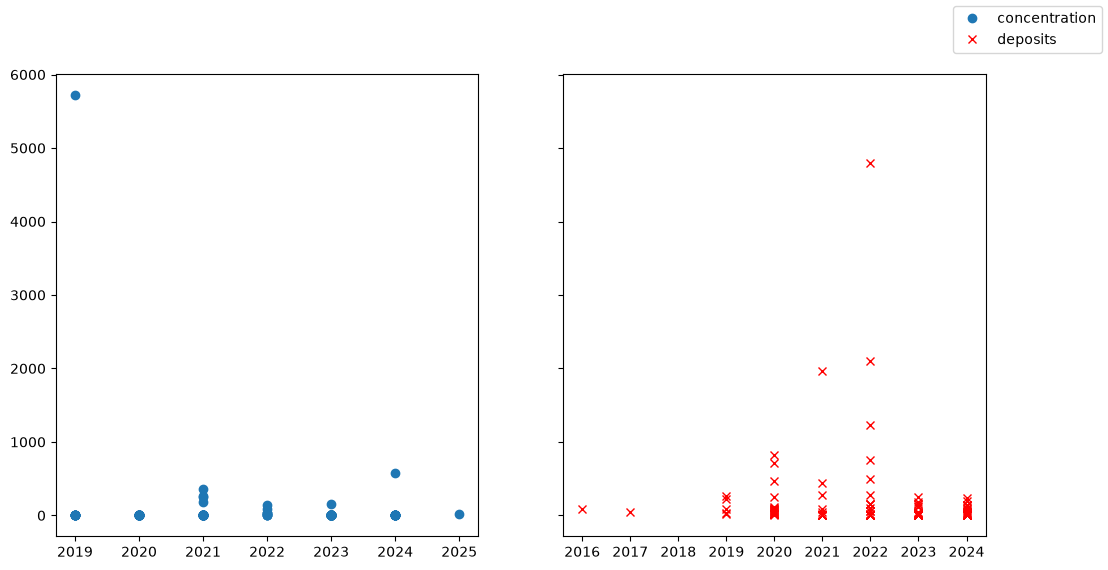

In [35]:
fig, axs = plt.subplots(1, 2, figsize=(12, 6), sharey=True)
axs[0].plot(concentrations["year"], concentrations["number"], "o", label="concentration")
axs[1].plot(deposits["year"], deposits["number"], "x", color="red", label="deposits")
fig.legend()

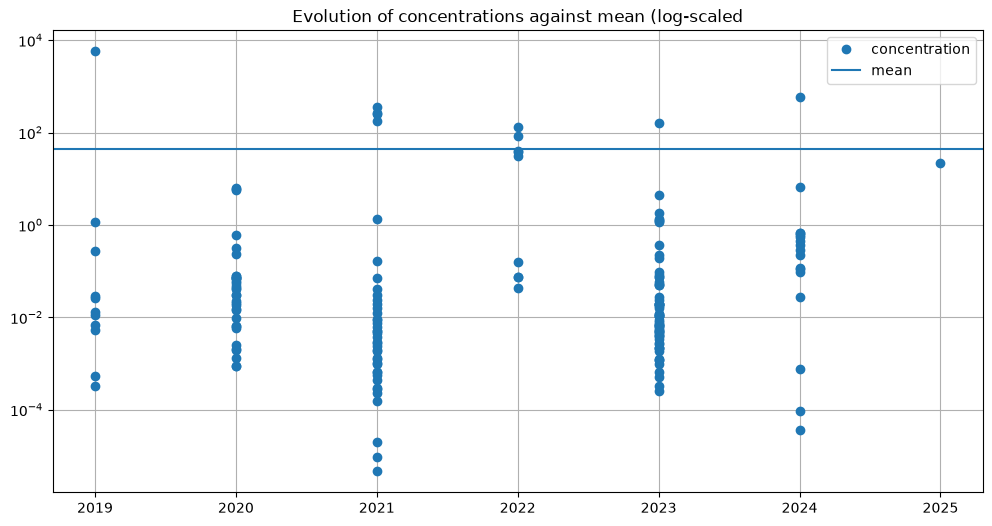

In [44]:
fig = plt.figure(figsize=(12, 6))
ax = fig.subplots(1, 1)
ax.plot(concentrations["year"], concentrations["number"], "o", label="concentration")
ax.axhline(conc_avg, label="mean")
ax.set_yscale("log")
ax.grid()
ax.set_title("Evolution of concentrations against mean (log-scaled")
ax.legend()